In [ ]:
import os
import json
import torch
import matplotlib.pyplot as plt


# ============================================================
# CONFIGURATION
# ============================================================

RESULTS_ROOT = "./results"

DATASETS = [
    "THEIA_E3",
    "THEIA_E5",
    "TRACE_E3",
    "TRACE_E5",
]

METHODS = [
    "flash",
    "velox",
    "orthrus",
]


TOP3_dic = {
    "THEIA_E3": 
    {
        "1": {
            "name" : "T2-C3",
            "percent": 37},
        "2":  {
            "name" : "T4-C9",
            "percent": 30},
        "3": {
            "name" : "T4-C3",
            "percent": 12},
    },
    "THEIA_E5": {
        "1": {
            "name" : "T4-C4",
            "percent": 65,},
        "2":  {
            "name" :"T4-C5" ,
            "percent": 18,},
        "3":  {
            "name" :"T1-C1" ,
            "percent": 13},
    },

    "TRACE_E3": {
        "1": {
            "name" : "T2-C3",
            "percent": 32,},
        "2":  {
            "name" : "T3-C8",
            "percent": 30,},
        "3":  {
            "name" : "T2-C2",
            "percent": 16},
    },

 "TRACE_E5": {
        "1": {
            "name" : "T1-C1",
            "percent": 68,},
        "2":  {
            "name" : "T4-C1",
            "percent": 11,},
        "3":  {
            "name" : "T2-C2" ,
            "percent": 5,},
    },

}




# ============================================================
# METRIC CALCULATION
# ============================================================

def calculate_metrics(results_path):

    data = torch.load(
        results_path,
        map_location="cpu"
    )

    tp = set()
    fp = set()
    tn = set()
    fn = set()

    for key, item in data.items():

        y_hat = item["y_hat"]
        y_true = item["y_true"]

        if y_hat == 1:

            if y_true == 1:
                tp.add(key)
            else:
                fp.add(key)

        else:

            if y_true == 1:
                fn.add(key)
            else:
                tn.add(key)

    tp = len(tp)
    fp = len(fp)
    tn = len(tn)
    fn = len(fn)

    eps = 1e-10

    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)

    f1 = (
        2 * precision * recall /
        (precision + recall + eps)
    )

    return {
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }


# ============================================================
# FIND RESULT FILE
# ============================================================

def find_result_file(dataset, method, configuration):

    path = os.path.join(
        RESULTS_ROOT,
        dataset,
        method,
        configuration,
        "results",
        "results.pth"
    )

    if os.path.exists(path):
        return path

    return None


# ============================================================
# DETERMINE CONFIGURATION
# ============================================================

def get_configurations():

    return [
        "base",
        "1",
        "2",
        "3",
    ]



# ============================================================
# COLLECT ALL RESULTS
# ============================================================

def collect_results():

    output = {}

    for dataset in DATASETS:

        output[dataset] = {}

        for method in METHODS:

            output[dataset][method] = {}

            for configuration in get_configurations():

                # Directory name
                if configuration == "base":
                    dirname = dataset.lower()
                    name = "base"
                else:
                    dirname = (
                        dataset.lower()
                        + "_"
                        + configuration
                    )
                    name = TOP3_dic[dataset][configuration]["name"]

                result_path = find_result_file(
                    dataset,
                    method,
                    dirname
                )

                if result_path is None:
                    print(
                        "MISSING:",
                        dataset,
                        method,
                        dirname
                    )
                    continue
                print(result_path)
                metrics = calculate_metrics(
                    result_path
                )
                
                output[dataset][method][name] = {
                    "TP": metrics["TP"],
                    "FP": metrics["FP"],
                    "TN": metrics["TN"],
                    "FN": metrics["FN"],
                    "precision": metrics["precision"],
                    "recall": metrics["recall"],
                    "f1": metrics["f1"],
                }

    return output


# ============================================================
# SAVE JSON
# ============================================================

results = collect_results()

with open(
    "Top3_Remove.json",
    "w"
) as f:

    json.dump(
        results,
        f,
        indent=4
    )

print(
    "\nSaved:",
    "Top3_Remove.json"
)



THEIA_E3
flash
base
./results\THEIA_E3\flash\theia_e3\results\results.pth
1
./results\THEIA_E3\flash\theia_e3_1\results\results.pth
2
./results\THEIA_E3\flash\theia_e3_2\results\results.pth
3
./results\THEIA_E3\flash\theia_e3_3\results\results.pth
velox
base
./results\THEIA_E3\velox\theia_e3\results\results.pth
1
./results\THEIA_E3\velox\theia_e3_1\results\results.pth
2
./results\THEIA_E3\velox\theia_e3_2\results\results.pth
3
./results\THEIA_E3\velox\theia_e3_3\results\results.pth
orthrus
base
./results\THEIA_E3\orthrus\theia_e3\results\results.pth
1
./results\THEIA_E3\orthrus\theia_e3_1\results\results.pth
2
./results\THEIA_E3\orthrus\theia_e3_2\results\results.pth
3
./results\THEIA_E3\orthrus\theia_e3_3\results\results.pth
THEIA_E5
flash
base
./results\THEIA_E5\flash\theia_e5\results\results.pth
1
./results\THEIA_E5\flash\theia_e5_1\results\results.pth
2
./results\THEIA_E5\flash\theia_e5_2\results\results.pth
3
./results\THEIA_E5\flash\theia_e5_3\results\results.pth
velox
base
./res

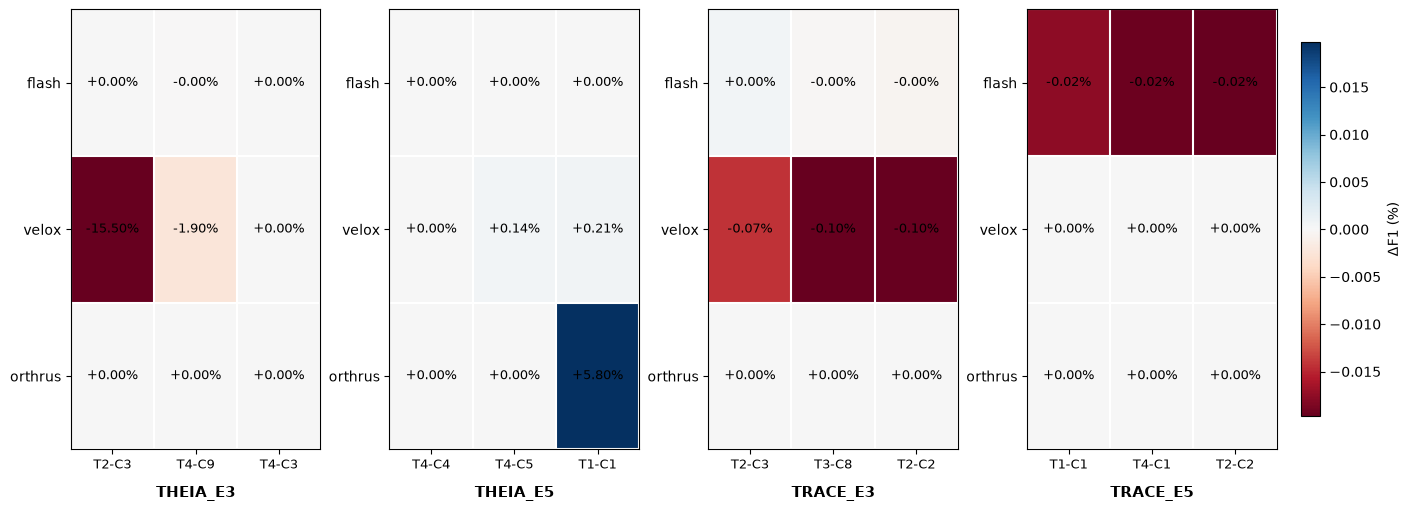

In [7]:
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

with open("Top3_Remove.json", "r") as f:
    data = json.load(f)

datasets = ["THEIA_E3", "THEIA_E5", "TRACE_E3", "TRACE_E5"]
methods = ["flash", "velox", "orthrus"]


def calculate_f1(tp, fp, fn):
    denom = 2 * tp + fp + fn
    return 0.0 if denom == 0 else 2 * tp / denom


fig, axes = plt.subplots(
    1, 4,
    figsize=(14, 5),
    constrained_layout=True
)

if len(datasets) == 1:
    axes = [axes]


for ax, dataset in zip(axes, datasets):

    dataset_data = data[dataset]

    profiles = [
        key for key in dataset_data["flash"].keys()
        if key != "base"
    ]

    matrix = []

    for method in methods:

        base = dataset_data[method]["base"]

        base_f1 = calculate_f1(
            base["TP"],
            base["FP"],
            base["FN"]
        )

        row = []

        for profile in profiles:

            result = dataset_data[method][profile]

            profile_f1 = calculate_f1(
                result["TP"],
                result["FP"],
                result["FN"]
            )

            # F1 difference as percentage
            difference = (profile_f1 - base_f1) * 100

            row.append(difference)

        matrix.append(row)

    matrix = np.array(matrix)

    max_abs = np.max(np.abs(matrix))
    if max_abs == 0:
        max_abs = 1

    norm = TwoSlopeNorm(
        vmin=-max_abs,
        vcenter=0,
        vmax=max_abs
    )

    im = ax.imshow(
        matrix,
        cmap="RdBu",
        norm=norm,
        aspect="auto"
    )

    # X axis: profiles
    ax.set_xticks(np.arange(len(profiles)))
    ax.set_xticklabels(
        profiles,
        fontsize=9
    )

    # Y axis: methods
    ax.set_yticks(np.arange(len(methods)))
    ax.set_yticklabels(
        methods,
        fontsize=10
    )

    # Dataset name UNDER the heatmap
    ax.set_xlabel(
        dataset,
        fontsize=11,
        fontweight="bold",
        labelpad=10
    )

    # Cell values
    for i in range(len(methods)):
        for j in range(len(profiles)):

            value = matrix[i, j]

            ax.text(
                j,
                i,
                f"{value:+.2f}%",
                ha="center",
                va="center",
                fontsize=9
            )

    # Cell borders
    ax.set_xticks(
        np.arange(-0.5, len(profiles), 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, len(methods), 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="white",
        linestyle="-",
        linewidth=1.5
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )


cbar = fig.colorbar(
    im,
    ax=axes,
    shrink=0.85,
    pad=0.02
)

cbar.set_label(
    "ΔF1 (%)",
    fontsize=10
)

plt.show()

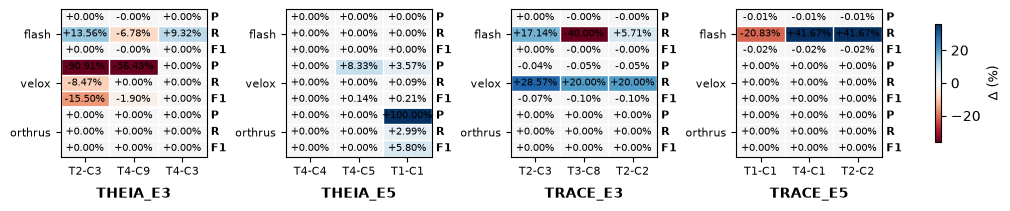

In [17]:
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

with open("Top3_Remove.json", "r") as f:
    data = json.load(f)

datasets = ["THEIA_E3", "THEIA_E5", "TRACE_E3", "TRACE_E5"]
methods = ["flash", "velox", "orthrus"]
metrics = ["Precision", "Recall", "F1"]


def calculate_metrics(tp, fp, fn):

    precision = tp / (tp + fp) if (tp + fp) != 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) != 0 else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) != 0
        else 0.0
    )

    return {
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }


# --------------------------------------------------
# Calculate all matrices
# --------------------------------------------------

all_matrices = {}

for dataset in datasets:

    dataset_data = data[dataset]

    profiles = [
        key for key in dataset_data["flash"].keys()
        if key != "base"
    ]

    matrix = []

    for method in methods:

        base = dataset_data[method]["base"]

        base_metrics = calculate_metrics(
            base["TP"],
            base["FP"],
            base["FN"]
        )

        for metric in metrics:

            row = []

            base_value = base_metrics[metric]

            for profile in profiles:

                result = dataset_data[method][profile]

                result_metrics = calculate_metrics(
                    result["TP"],
                    result["FP"],
                    result["FN"]
                )

                result_value = result_metrics[metric]

                difference = (result_value - base_value) * 100

                row.append(difference)

            matrix.append(row)

    all_matrices[dataset] = np.array(matrix)


# --------------------------------------------------
# Color scale
# Use 95th percentile instead of maximum
# --------------------------------------------------

all_values = np.concatenate([
    matrix.flatten()
    for matrix in all_matrices.values()
])

max_abs = np.percentile(
    np.abs(all_values),
    95
)

if max_abs == 0:
    max_abs = 1

norm = TwoSlopeNorm(
    vmin=-max_abs,
    vcenter=0,
    vmax=max_abs
)


# --------------------------------------------------
# Plot
# Height divided by 3
# --------------------------------------------------

fig, axes = plt.subplots(
    1,
    4,
    figsize=(10, 2.0),
    constrained_layout=True
)


for ax, dataset in zip(axes, datasets):

    matrix = all_matrices[dataset]

    profiles = [
        key for key in data[dataset]["flash"].keys()
        if key != "base"
    ]

    im = ax.imshow(
        matrix,
        cmap="RdBu",
        norm=norm,
        aspect="auto"
    )

    # ----------------------------------------------
    # X axis
    # ----------------------------------------------

    ax.set_xticks(np.arange(len(profiles)))
    ax.set_xticklabels(
        profiles,
        fontsize=8
    )

    # ----------------------------------------------
    # Y axis: method only once per 3 rows
    # ----------------------------------------------

    ax.set_yticks([
        1,
        4,
        7
    ])

    ax.set_yticklabels(
        methods,
        fontsize=8
    )

    # ----------------------------------------------
    # P / R / F1 on the right
    # Closer to the heatmap
    # ----------------------------------------------

    for i, method in enumerate(methods):

        start = i * 3

        for j, metric in enumerate(["P", "R", "F1"]):

            ax.annotate(
            metric,
            xy=(1, start + j),
            xycoords=("axes fraction", "data"),
            xytext=(3, 0),
            textcoords="offset points",
            ha="left",
            va="center",
            fontsize=8,
            fontweight="bold")

    # ----------------------------------------------
    # Dataset name
    # ----------------------------------------------

    ax.set_xlabel(
        dataset,
        fontsize=10,
        fontweight="bold",
        labelpad=7
    )

    # ----------------------------------------------
    # Values
    # ----------------------------------------------

    for i in range(matrix.shape[0]):

        for j in range(matrix.shape[1]):

            value = matrix[i, j]

            ax.text(
                j,
                i,
                f"{value:+.2f}%",
                ha="center",
                va="center",
                fontsize=7
            )

    # ----------------------------------------------
    # Separators between methods
    # ----------------------------------------------

    for y in [2.5, 5.5]:

        ax.axhline(
            y,
            color="white",
            linewidth=2
        )

    # ----------------------------------------------
    # Cell borders
    # ----------------------------------------------

    ax.set_xticks(
        np.arange(-0.5, len(profiles), 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, len(matrix), 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="white",
        linestyle="-",
        linewidth=1
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )


# --------------------------------------------------
# Colorbar
# --------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=axes,
    shrink=0.8,
    pad=0.04
)

cbar.set_label(
    "Δ (%)",
    fontsize=9
)

plt.show()